In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080101
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] ML
[学号] 20244080101
[机器指纹] c8c5ea6ebc227d20
[RUN_ID] 20244080101-c8c5ea6ebc227d20


实验1：NumPy 数组、数据类型与索引

In [2]:
#实验一
print("\n第一部分")
import numpy as np

a_int = np.array([1, 2, 3, 4])
a_float = np.array([1.0, 2.5, 3.14])
a_bool = np.array([True, False, True, False])
for name, arr in (("整数", a_int), ("浮点", a_float), ("布尔", a_bool)):
    print(f"{name}: {arr} | dtype={arr.dtype} | shape={arr.shape} | ndim={arr.ndim}")

print("\n第二部分")
arr = np.arange(12)
print("原始:", arr, arr.shape)

a34 = arr.reshape(3, 4)
print("(3,4):\n", a34)
print("shape:", a34.shape)

a232 = arr.reshape(2, 3, 2)
print("(2,3,2):\n", a232)
print("shape:", a232.shape, "| 元素总数:", a232.size)

try:
    arr.reshape(5, 3)
except ValueError as e:
    print("(5,3) 失败:", e)

print("\n第三部分")
row2 = a34[1, :]
print("第2行:", row2, "shape=", row2.shape)

cols13 = a34[:, 0:3]
print("第1至第3列:\n", cols13, "shape=", cols13.shape)

big = a34[a34 > 6]
print("大于6的元素:", big, "shape=", big.shape)

print("\n第四部分")
x = np.arange(10)
print("原数组:", x)

m1 = (x < 2) | (x > 7)
print("小于2或大于7 (|):", x[m1])
m2 = np.logical_or(x < 2, x > 7)
print("小于2或大于7 (logical_or):", x[m2])

m3 = (x > 3) & (x < 7)
print("大于3且小于7 (&):", x[m3])
m4 = np.logical_and(x > 3, x < 7)
print("大于3且小于7 (logical_and):", x[m4])

print("\n第五部分")
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A:\n", A)
print("B:\n", B)

print("A * B (逐元素):\n", A * B)
print("np.multiply:\n", np.multiply(A, B))
print("A @ B (矩阵乘):\n", A @ B)
print("np.matmul:\n", np.matmul(A, B))


第一部分
整数: [1 2 3 4] | dtype=int64 | shape=(4,) | ndim=1
浮点: [1.   2.5  3.14] | dtype=float64 | shape=(3,) | ndim=1
布尔: [ True False  True False] | dtype=bool | shape=(4,) | ndim=1

第二部分
原始: [ 0  1  2  3  4  5  6  7  8  9 10 11] (12,)
(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape: (3, 4)
(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
shape: (2, 3, 2) | 元素总数: 12
(5,3) 失败: cannot reshape array of size 12 into shape (5,3)

第三部分
第2行: [4 5 6 7] shape= (4,)
第1至第3列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape= (3, 3)
大于6的元素: [ 7  8  9 10 11] shape= (5,)

第四部分
原数组: [0 1 2 3 4 5 6 7 8 9]
小于2或大于7 (|): [0 1 8 9]
小于2或大于7 (logical_or): [0 1 8 9]
大于3且小于7 (&): [4 5 6]
大于3且小于7 (logical_and): [4 5 6]

第五部分
A:
 [[1 2]
 [3 4]]
B:
 [[5 6]
 [7 8]]
A * B (逐元素):
 [[ 5 12]
 [21 32]]
np.multiply:
 [[ 5 12]
 [21 32]]
A @ B (矩阵乘):
 [[19 22]
 [43 50]]
np.matmul:
 [[19 22]
 [43 50]]


第一部分\
说明：Python 列表里可以混放不同类型（[1, "a", 3.5]），每个元素是独立对象，没办法整体统一类型；NumPy 数组所有元素共享同一个 dtype（int64 / float64 / bool），底层是一段连续内存。因此 NumPy 能用等宽字节存储、支持向量化运算，而列表需要靠循环逐个处理。

第二部分\
说明：reshape 要求新形状各维度的乘积必须等于元素总数，且只改变“解释方式”，不复制数据。12 = 3×4 = 2×3×2 都可以；5×3 = 15 ≠ 12，所以报 cannot reshape array of size 12 into shape (5,3)。

第五部分\
区别：* / np.multiply 是对应位置相乘（Hadamard 积），要求形状相同或可广播；@ / np.matmul 是线性代数矩阵乘法，要求左矩阵列数 = 右矩阵行数。

实验2：随机抽样、统计与缺失值

In [3]:
#实验二
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)

print("\n第一部分")
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print(f"样本数: {scores.size}")
print(f"最小值: {scores.min():.4f}")
print(f"最大值: {scores.max():.4f}")
print(f"均值:   {scores.mean():.4f}")
print(f"标准差: {scores.std():.4f}")
print(f"极差:   {scores.max() - scores.min():.4f}")

print("\n第二部分")
pool = np.arange(1, 11)

np.random.seed(SEED)
uniform = np.random.choice(pool, size=5, replace=False)
print("均匀抽样:  ", uniform)

weights = pool / pool.sum()
np.random.seed(SEED)
weighted = np.random.choice(pool, size=5, replace=False, p=weights)
print("加权抽样:  ", weighted)
print("权重:", np.round(weights, 4))

print("\n第三部分")
arr = np.arange(10)
print("原始数组:      ", arr)
perm = np.random.permutation(arr)
print("permutation 后: 原数组 =", arr, "| 新数组 =", perm)

arr2 = np.arange(10)
print("\n原始数组:      ", arr2)
np.random.shuffle(arr2)
print("shuffle 后:    原数组 =", arr2, "(已被原地修改)")

print("\n第四部分")
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan      # 第10、20、30个（索引从0开始）

plain_mean = scores_nan.mean()
nan_mean = np.nanmean(scores_nan)
print(f"普通均值 np.mean:    {plain_mean}")
print(f"忽略缺失 np.nanmean: {nan_mean:.4f}")
print(f"缺失值个数: {np.sum(np.isnan(scores_nan))}")

print("\n第五部分")
df_scores = pd.DataFrame({
    "序号": np.arange(1, len(scores_nan) + 1),
    "成绩": scores_nan,
})
print(df_scores.head(8))
print("shape:", df_scores.shape, "| 缺失数:", int(df_scores["成绩"].isna().sum()))


第一部分
样本数: 1000
最小值: 37.5873
最大值: 100.0000
均值:   70.1840
标准差: 9.7551
极差:   62.4127

第二部分
均匀抽样:   [9 2 6 1 8]
加权抽样:   [ 6 10  9  8  4]
权重: [0.0182 0.0364 0.0545 0.0727 0.0909 0.1091 0.1273 0.1455 0.1636 0.1818]

第三部分
原始数组:       [0 1 2 3 4 5 6 7 8 9]
permutation 后: 原数组 = [0 1 2 3 4 5 6 7 8 9] | 新数组 = [0 1 8 5 3 4 7 9 6 2]

原始数组:       [0 1 2 3 4 5 6 7 8 9]
shuffle 后:    原数组 = [9 2 0 6 8 5 3 7 1 4] (已被原地修改)

第四部分
普通均值 np.mean:    nan
忽略缺失 np.nanmean: 70.1962
缺失值个数: 3

第五部分
   序号         成绩
0   1  74.967142
1   2  68.617357
2   3  76.476885
3   4  85.230299
4   5  67.658466
5   6  67.658630
6   7  85.792128
7   8  77.674347
shape: (1000, 2) | 缺失数: 3


第四部分\
说明：NaN 参与运算会“污染”整个结果——mean / sum / std 全是 nan，因为它们逐元素累加，遇到 NaN 就变成 NaN。np.nanmean / np.nansum / np.nanstd 会先屏蔽 NaN 再统计。缺失个数用 np.isnan() 得到布尔数组后 np.sum()（True 记为 1）。

实验3：SciPy 数值计算与 Matplotlib 可视化


第一部分
解 x = [2. 3.]
NumPy 验证 A @ x = [9. 8.] | 与 b 接近: True

第二部分
x0=+1 | success=True | x=1.4142135624 | 函数值=-8.882e-16 | 接近0: [ True]
x0=-1 | success=True | x=-1.4142135624 | 函数值=-8.882e-16 | 接近0: [ True]
理论值 ±sqrt(2) = 1.4142135623730951

第三部分
success: True
极小点 x = [-0.50000001] | 函数值 f(x) = 1.75
解析解 x = -b/(2a) = -0.5 | f(-0.5) = 1.75

第四部分
组1: mean=-0.1038, std=0.9082
组2: mean=1.0223, std=0.9537
t = -8.5515 | p = 3.293e-15
p < 0.05 -> 拒绝原假设，两组均值差异显著

第五部分
有效成绩个数: 997


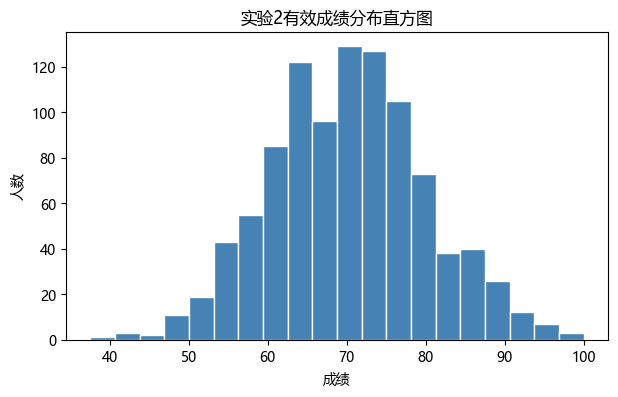

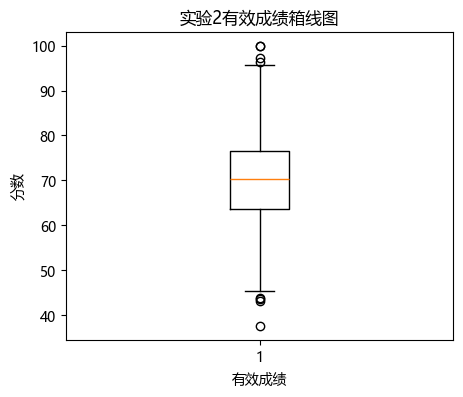

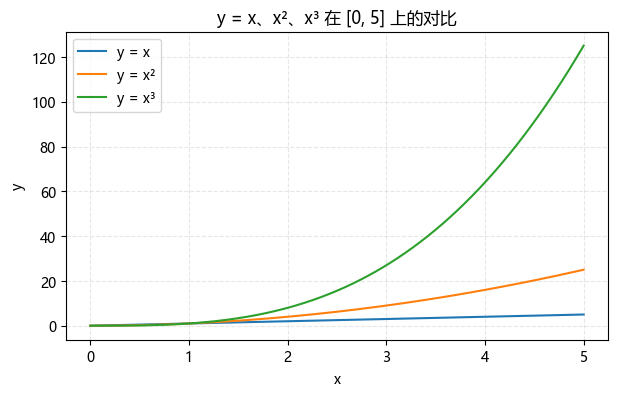

In [4]:
#实验三
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# 中文显示设置，避免标题/标签变成方块
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

print("\n第一部分")
from scipy.linalg import solve

A = np.array([[3.0, 1.0], [1.0, 2.0]])
b = np.array([9.0, 8.0])

x = solve(A, b)
print("解 x =", x)
print("NumPy 验证 A @ x =", A @ x, "| 与 b 接近:", np.allclose(A @ x, b))

print("\n第二部分")
from scipy.optimize import root

def g(x):
    return x**2 - 2

for x0 in (1.0, -1.0):
    res = root(g, x0)
    f_val = g(res.x)
    close_to_zero = np.isclose(f_val, 0, atol=1e-8)
    print(f"x0={x0:+.0f} | success={res.success} | x={res.x[0]:.10f} | 函数值={f_val[0]:.3e} | 接近0: {close_to_zero}")

print("理论值 ±sqrt(2) =", np.sqrt(2))

print("\n第三部分")
from scipy.optimize import minimize

def f(x):
    return x**2 + x + 2

res_min = minimize(f, x0=0.0)
print("success:", res_min.success)
print("极小点 x =", res_min.x, "| 函数值 f(x) =", res_min.fun)

analytic_x = -1 / (2 * 1)
print("解析解 x = -b/(2a) =", analytic_x, "| f(-0.5) =", (-0.5)**2 + (-0.5) + 2)

print("\n第四部分")
from scipy import stats

np.random.seed(SEED)
group1 = np.random.normal(loc=0, scale=1, size=100)
group2 = np.random.normal(loc=1, scale=1, size=100)

print(f"组1: mean={group1.mean():.4f}, std={group1.std(ddof=1):.4f}")
print(f"组2: mean={group2.mean():.4f}, std={group2.std(ddof=1):.4f}")

t_stat, p_val = stats.ttest_ind(group1, group2)
print(f"t = {t_stat:.4f} | p = {p_val:.3e}")

alpha = 0.05
if p_val < alpha:
    print(f"p < {alpha} -> 拒绝原假设，两组均值差异显著")
else:
    print(f"p >= {alpha} -> 不能拒绝原假设，差异不显著")

print("\n第五部分")
# 依赖实验2第五部分生成的 df_scores；已剔除 NaN 得到“有效成绩”
valid_scores = df_scores["成绩"].dropna().to_numpy()
print("有效成绩个数:", valid_scores.size)

# 1) 直方图
plt.figure(figsize=(7, 4))
plt.hist(valid_scores, bins=20, color="steelblue", edgecolor="white")
plt.title("实验2有效成绩分布直方图")
plt.xlabel("成绩")
plt.ylabel("人数")
plt.show()

# 2) 箱线图
plt.figure(figsize=(5, 4))
plt.boxplot(valid_scores)
plt.title("实验2有效成绩箱线图")
plt.xlabel("有效成绩")
plt.ylabel("分数")
plt.show()

# 3) 三条曲线同坐标系
xs = np.linspace(0, 5, 200)
plt.figure(figsize=(7, 4))
plt.plot(xs, xs,     label="y = x")
plt.plot(xs, xs**2,  label="y = x²")
plt.plot(xs, xs**3,  label="y = x³")
plt.title("y = x、x²、x³ 在 [0, 5] 上的对比")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3, linestyle="--")
plt.show()

实验4：pandas Series、DataFrame 与内存中的CSV 读写

In [5]:
#实验四
import numpy as np
import pandas as pd

pd.set_option("display.unicode.east_asian_width", True)

print("\n第一部分")
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print(df)
print("行索引:", list(df.index))
print("列名:", list(df.columns))
print("\n前3行:\n", df.head(3))
print("\n基本统计:\n", df.describe())

print("\n第二部分")
print("loc['Carol']:\n", df.loc["Carol"])
print("\niloc[2]:\n", df.iloc[2])
print("\n平均分>=80:\n", df[df["Average"] >= 80])

print("\n第三部分")
subjects = ["Math", "English", "Python"]
print("mean(axis=0) 列均值:\n", df[subjects].mean(axis=0))
print("\nmean(axis=1) 行均值:\n", df[subjects].mean(axis=1))

print("\n第四部分")
df["Max"] = df[subjects].apply(np.max, axis=1)
print("每人三科最高分:\n", df["Max"])

print("\nagg 每科 min/mean/max:\n", df[subjects].agg(["min", "mean", "max"]))

df["Rank_Python"] = df["Python"].rank(ascending=False)
print("\nPython 排名:\n", df[["Python", "Rank_Python"]].sort_values("Rank_Python"))

print("\n第五部分")
grp = df.groupby("Group")
print("每组人数:\n", grp.size())
print("\n每组三科平均:\n", grp[subjects].mean())

df["Group_Python_Mean"] = grp["Python"].transform("mean")
print("\n加组内Python平均:\n", df[["Group", "Python", "Group_Python_Mean"]])

print("\n第六部分")
keep = grp.filter(lambda g: g["Python"].mean() >= 80)
print(keep[["Group", "Python", "Average", "Group_Python_Mean"]])

print("\n第七部分")
sub = df[subjects]
print("协方差:\n", sub.cov())
print("\n相关系数:\n", sub.corr())

print("\nMath~Python 协方差:", round(sub["Math"].cov(sub["Python"]), 4))
print("Math~Python 相关系数:", round(sub["Math"].corr(sub["Python"]), 4))


第一部分
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
David     B    65       73      70    208  69.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000
行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333

第七部分\
说明：Math 与 Python 的协方差是 +74.93，符号为正 → 两科同向变化（数学高的人 Python 通常也高）。相关系数 0.8848，绝对值接近 1 → 强正线性相关。协方差的大小受量纲影响（换成分数制就会变），所以判断强弱要看相关系数（范围固定 −1～1）。